In [ ]:
 p install -q kagglehub

In [ ]:
import kagglehub

path = kagglehub.dataset_download("xhlulu/140k-real-and-fake-faces")

print("Dataset downloaded to:")
print(path)

Using Colab cache for faster access to the '140k-real-and-fake-faces' dataset.
Dataset downloaded to:
/kaggle/input/140k-real-and-fake-faces


In [ ]:
import os

print(os.listdir(path))

['valid.csv', 'real_vs_fake', 'train.csv', 'test.csv']


In [ ]:
!find /content -maxdepth 3 -type d | head -100

/content
/content/.config
/content/.config/configurations
/content/.config/logs
/content/.config/logs/2026.10.21
/content/drive
/content/drive/.shortcut-targets-by-id
/content/drive/MyDrive
/content/drive/MyDrive/Colab Notebooks
/content/drive/MyDrive/deepfake image detection
/content/drive/MyDrive/AI_Image_Detector
/content/drive/.Trash-0
/content/drive/.Trash-0/files
/content/drive/.Trash-0/info
/content/drive/.Encrypted
/content/drive/.Encrypted/.shortcut-targets-by-id
/content/drive/.Encrypted/MyDrive
/content/sample_data


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
!nvidia-smi

Wed Nov 11 04:28:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P0             28W /   70W |     181MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
PyTorch CUDA version: 13.0
CUDA available: True


In [ ]:
!python --version
!pip show torch

Python 3.13.16
Name: torch
Version: 2.14.1+cu130
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License-Expression: Apache-2.0 AND Apache-2.0 WITH LLVM-exception AND BSD-2-Clause AND BSD-3-Clause AND BSL-1.0 AND MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu13, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvshmem-cu13, setuptools, sympy, triton, typing-extensions
Required-by: accelerate, fastai, peft, sentence-transformers, timm, torchdata, torchvision


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

Device: cuda
GPU: Tesla T4
VRAM: 14.56 GB


In [ ]:
import torch
import time

device = torch.device("cuda")

x = torch.randn(32, 3, 224, 224).to(device)

start = time.time()

for _ in range(100):
    y = x * 2

torch.cuda.synchronize()

print("Time:", time.time() - start, "seconds")

Time: 0.0166778564453125 seconds


In [ ]:
!find /kaggle/input/140k-real-and-fake-faces -maxdepth 3 -type d

/kaggle/input/140k-real-and-fake-faces
/kaggle/input/140k-real-and-fake-faces/real_vs_fake
/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake
/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/valid
/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test
/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/train


In [ ]:
import os

DATASET_PATH = "/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake"

for split in ["train", "valid", "test"]:
    path = os.path.join(DATASET_PATH, split)
    print(f"\n{split.upper()}:")
    print(os.listdir(path))


TRAIN:
['fake', 'real']

VALID:
['fake', 'real']

TEST:
['fake', 'real']


In [ ]:
from pathlib import Path

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")

    for cls in ["real", "fake"]:
        path = Path(DATASET_PATH) / split / cls
        count = len(list(path.glob("*")))
        print(f"{cls}: {count}")


TRAIN
real: 50000
fake: 50000

VALID
real: 10000
fake: 10000

TEST
real: 10000
fake: 10000


In [ ]:
import os

DATASET_PATH = "/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake"

TRAIN_DIR = os.path.join(DATASET_PATH, "train")
VALID_DIR = os.path.join(DATASET_PATH, "valid")
TEST_DIR = os.path.join(DATASET_PATH, "test")

print("Train:", TRAIN_DIR)
print("Valid:", VALID_DIR)
print("Test :", TEST_DIR)

print("\nTrain exists:", os.path.exists(TRAIN_DIR))
print("Valid exists:", os.path.exists(VALID_DIR))
print("Test exists :", os.path.exists(TEST_DIR))

Train: /kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/train
Valid: /kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/valid
Test : /kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test

Train exists: True
Valid exists: True
Test exists : True


In [ ]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

Torch: 2.14.1+cu130
Torchvision: 0.29.1+cu130


In [ ]:
#image preprocessing
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

valid_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
#datasets
train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    VALID_DIR,
    transform=valid_test_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=valid_test_transform
)

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

print("\nTrain:", len(train_dataset))
print("Valid:", len(valid_dataset))
print("Test :", len(test_dataset))

Classes: ['fake', 'real']
Class mapping: {'fake': 0, 'real': 1}

Train: 100000
Valid: 20000
Test : 20000


In [ ]:
#data loaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Valid batches:", len(valid_loader))
print("Test batches :", len(test_loader))

Train batches: 1563
Valid batches: 313
Test batches : 313


In [ ]:
#test data loader
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels[:10])

Image shape: torch.Size([64, 3, 224, 224])
Labels shape: torch.Size([64])
Labels: tensor([0, 0, 0, 0, 0, 0, 0, 1, 1, 0])


In [ ]:
#set gpu
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [ ]:
#load ResNet50
weights = models.ResNet50_Weights.DEFAULT

model = models.resnet50(weights=weights)

In [ ]:
#replace final layer to 0 and 1
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 2)

model = model.to(device)
print(model.fc)

Linear(in_features=2048, out_features=2, bias=True)


In [ ]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 4098


In [ ]:
#loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [ ]:
#Training
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
#validation
def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
#quick test on 5000 dataset
QUICK_TEST_EPOCHS = 1
from torch.utils.data import Subset

quick_train_dataset = Subset(train_dataset, range(5000))
quick_valid_dataset = Subset(valid_dataset, range(1000))

quick_train_loader = DataLoader(
    quick_train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

quick_valid_loader = DataLoader(
    quick_valid_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)
loss, acc = train_one_epoch(
    model,
    quick_train_loader,
    criterion,
    optimizer,
    device
)

val_loss, val_acc = evaluate(
    model,
    quick_valid_loader,
    criterion,
    device
)

print("Training loss:", loss)
print("Training accuracy:", acc)

print("Validation loss:", val_loss)
print("Validation accuracy:", val_acc)

Training loss: 0.04434127615615725
Training accuracy: 0.996
Validation loss: 0.004489290114492178
Validation accuracy: 1.0


In [ ]:
#fresh model ResNet50 and check full loaders
weights = models.ResNet50_Weights.DEFAULT

model = models.resnet50(weights=weights)

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)

model = model.to(device)
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)
print("Full train dataset:", len(train_loader.dataset))
print("Full validation dataset:", len(valid_loader.dataset))
print("Full test dataset:", len(test_loader.dataset))

print("Train batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))

Full train dataset: 100000
Full validation dataset: 20000
Full test dataset: 20000
Train batches: 1563
Validation batches: 313
Test batches: 313


In [ ]:
#running a full epoch1
import time

start = time.time()

train_loss, train_acc = train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device
)

val_loss, val_acc = evaluate(
    model,
    valid_loader,
    criterion,
    device
)

elapsed = time.time() - start

print(f"Training Loss: {train_loss:.4f}")
print(f"Training Accuracy: {train_acc*100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc*100:.2f}%")
print(f"Time: {elapsed/60:.2f} minutes")
#save epoch1
torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx,
    "val_accuracy": 0.8616,
    "epoch": 1
}, "/content/deepfake_resnet50_best.pth")

KeyboardInterrupt: 

In [ ]:
#running remaining 2-5 epoch
optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)
EPOCHS = 4

best_val_accuracy = 0.8616

for epoch in range(EPOCHS):

    start = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        valid_loader,
        criterion,
        device
    )

    elapsed = (time.time() - start) / 60

    print(f"\nEpoch {epoch + 2}/5")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_acc*100:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc*100:.2f}%")
    print(f"Time: {elapsed:.2f} minutes")

    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_to_idx": train_dataset.class_to_idx,
            "val_accuracy": val_acc,
            "epoch": epoch + 2
        }, "/content/deepfake_resnet50_best.pth")

        print("Best model saved!")


Epoch 2/5
Training Loss: 0.3478
Training Accuracy: 84.95%
Validation Loss: 0.3170
Validation Accuracy: 86.81%
Time: 11.23 minutes
Best model saved!

Epoch 3/5
Training Loss: 0.3422
Training Accuracy: 85.32%
Validation Loss: 0.3162
Validation Accuracy: 86.72%
Time: 11.18 minutes

Epoch 4/5
Training Loss: 0.3397
Training Accuracy: 85.52%
Validation Loss: 0.3126
Validation Accuracy: 86.94%
Time: 11.17 minutes
Best model saved!

Epoch 5/5
Training Loss: 0.3378
Training Accuracy: 85.49%
Validation Loss: 0.3096
Validation Accuracy: 86.96%
Time: 11.08 minutes
Best model saved!


In [ ]:
#Load best model
checkpoint = torch.load(
    "/content/deepfake_resnet50_best.pth",
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best model loaded!")
print("Saved Epoch:", checkpoint["epoch"])
print("Validation Accuracy:", checkpoint["val_accuracy"])
print("Class Mapping:", checkpoint["class_to_idx"])

NameError: name 'device' is not defined

In [ ]:
#test dataset
print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("Classes:", test_dataset.class_to_idx)

NameError: name 'test_dataset' is not defined

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#MODEL FOLDER
import os

MODEL_DIR = "/content/drive/MyDrive/AI_Image_Detector"

os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = f"{MODEL_DIR}/ai_image_detector_resnet50.pth"

print(MODEL_PATH)

/content/drive/MyDrive/AI_Image_Detector/ai_image_detector_resnet50.pth


In [ ]:
#SAVE MODEL TO DRIVE
torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx
}, MODEL_PATH)

print("Model saved successfully!")
print(MODEL_PATH)

NameError: name 'model' is not defined

In [ ]:
#Test Accuracy
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Total Test Images: {total}")
print(f"Correct Predictions: {correct}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Total Test Images: 20000
Correct Predictions: 17462
Test Accuracy: 87.31%


Confusion Matrix:
[[8944 1056]
 [1482 8518]]


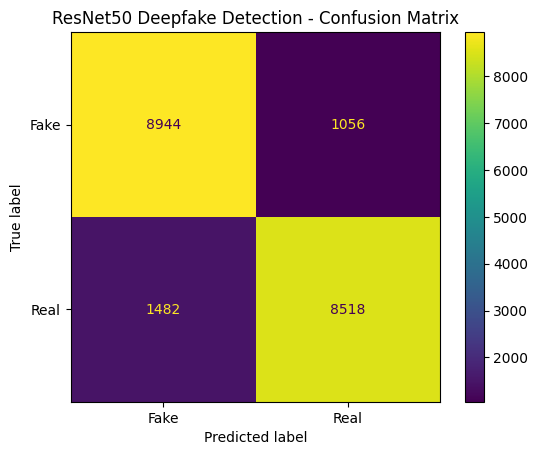

In [ ]:
#confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

class_names = ['Fake', 'Real']

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot()
plt.title("ResNet50 Deepfake Detection - Confusion Matrix")
plt.show()

In [ ]:
# Precision, Recall and F1 Score
from sklearn.metrics import classification_report

class_names = ['Fake', 'Real']

report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

        Fake       0.86      0.89      0.88     10000
        Real       0.89      0.85      0.87     10000

    accuracy                           0.87     20000
   macro avg       0.87      0.87      0.87     20000
weighted avg       0.87      0.87      0.87     20000



In [ ]:
#recreate resnet architecture and load saved weights
import torch
from torch import nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = "/content/drive/MyDrive/AI_Image_Detector/ai_image_detector_resnet50.pth"

model = models.resnet50(
    weights=None
)

num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    2
)
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)

model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
#test new data
from google.colab import files
uploaded = files.upload()
from PIL import Image
import torch
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Get uploaded filename
image_path = list(uploaded.keys())[0]

# Same preprocessing used during training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
# Load image
image = Image.open(image_path).convert("RGB")
# Preprocess
image_tensor = transform(image).unsqueeze(0).to(device)
# Prediction
model.eval()
with torch.no_grad():
    output = model(image_tensor)
    probabilities = torch.softmax(output, dim=1)
    confidence, predicted = torch.max(probabilities, 1)
# Class names
class_names = ['Fake', 'Real']
prediction = class_names[predicted.item()]
confidence = confidence.item() * 100
print(f"Prediction: {prediction}")
print(f"Confidence: {confidence:.2f}%")
# Display image
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title(f"{prediction} ({confidence:.2f}%)")
plt.show()

with torch.no_grad():
    output = model(image_tensor)
    probabilities = torch.softmax(output, dim=1)

print("Fake probability:", probabilities[0][0].item() * 100)
print("Real probability:", probabilities[0][1].item() * 100)

Saving WhatsApp Image 2026-09-25 at 22.30.08-350x466.jpeg to WhatsApp Image 2026-09-25 at 22.30.08-350x466 (1).jpeg


NameError: name 'device' is not defined